# 2 · The full-context regime: when everything fits, selection is already solved

*Part 2 of the story. Previously: `01_setup_and_data.ipynb`.*

**What this notebook answers.** With all candidates on the table, where does the
difficulty actually live? (Spoiler: not in choosing between them.)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


FULL = al.find_run("skeleton")
full = al.load_answers(FULL)
metrics = al.load_metrics(FULL)
senses = al.load_senses_table().set_index("sense_id")

acc = al.accuracy_frame([FULL]).set_index("variant")
acc[["n", "citation_accuracy", "citation_accuracy_excl_trick", "retrieval_errors", "composition_errors", "mrr"]]

,n,citation_accuracy,citation_accuracy_excl_trick,retrieval_errors,composition_errors,mrr
variant,,,,,,
A,36,NaN,NaN,NaN,NaN,NaN
B,36,0.306,0.294,22.0,3.0,0.217
C,36,0.944,1.000,0.0,2.0,NaN
D,36,0.944,1.000,0.0,2.0,NaN
oracle,36,0.944,1.000,0.0,2.0,NaN


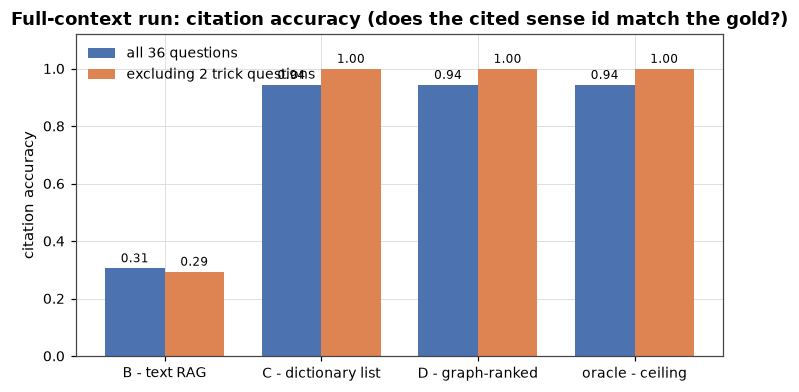

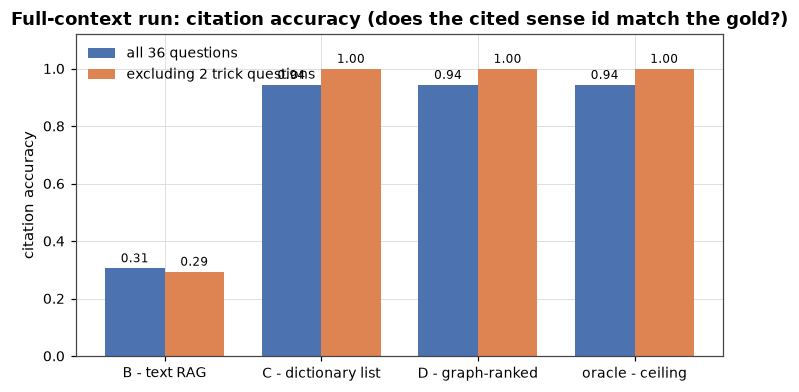

In [2]:
order = ["B", "C", "D", "oracle"]
x = np.arange(len(order))
w = 0.38

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.bar(x - w / 2, [acc.loc[v, "citation_accuracy"] for v in order], w, color="#4c72b0", label="all 36 questions")
ax.bar(x + w / 2, [acc.loc[v, "citation_accuracy_excl_trick"] for v in order], w, color="#dd8452", label="excluding 2 trick questions")
for i, v in enumerate(order):
    ax.text(i - w / 2, acc.loc[v, "citation_accuracy"] + 0.02, f"{acc.loc[v, 'citation_accuracy']:.2f}", ha="center", fontsize=8)
    ax.text(i + w / 2, acc.loc[v, "citation_accuracy_excl_trick"] + 0.02, f"{acc.loc[v, 'citation_accuracy_excl_trick']:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [al.VARIANT_LABELS[v] for v in order])
ax.set_ylabel("citation accuracy")
ax.set_ylim(0, 1.12)
ax.set_title("Full-context run: citation accuracy (does the cited sense id match the gold?)")
ax.legend(loc="upper left")
al.save_figure(fig, "02_accuracy_full")
fig

> **Reading the chart.** C, D and oracle are indistinguishable: **34/34 = 100 %**
> once the two flawed items are removed - and the oracle control proves that
> the *selection* step was never the problem: even with the gold guaranteed
> on the table, the model scores the same. B is far behind (10/34 = 29 %).
> (Variant A cannot cite IDs at all; its free-text answers are scored
> separately in notebook 5.)

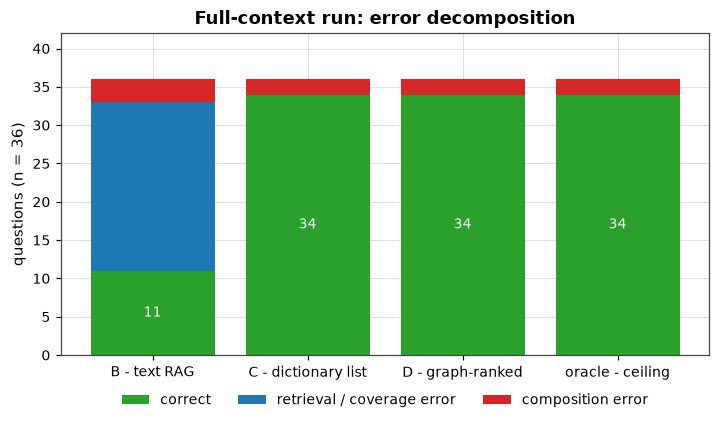

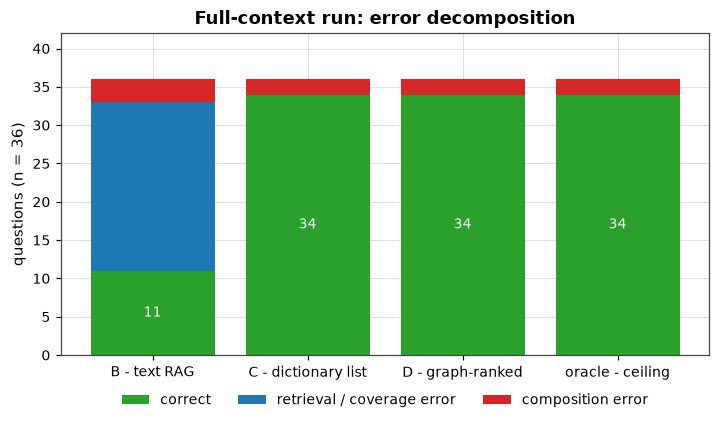

In [3]:
variants = ["B", "C", "D", "oracle"]
correct, retrieval, composition = [], [], []
for v in variants:
    sub = full[full["variant"] == v]
    comp = int(metrics["variants"][v].get("composition_errors", 0))
    c = int(sub["correct"].sum())
    correct.append(c)
    composition.append(comp)
    retrieval.append(len(sub) - c - comp)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
x = np.arange(len(variants))
ax.bar(x, correct, color="#2ca02c", label="correct")
ax.bar(x, retrieval, bottom=correct, color="#1f77b4", label="retrieval / coverage error")
ax.bar(x, composition, bottom=np.array(correct) + np.array(retrieval), color="#d62728", label="composition error")
for i in range(len(variants)):
    ax.text(i, correct[i] / 2, str(correct[i]), ha="center", va="center", color="white", fontsize=9)
ax.set_xticks(x, [al.VARIANT_LABELS[v] for v in variants])
ax.set_ylabel("questions (n = 36)")
ax.set_ylim(0, 42)
ax.set_title("Full-context run: error decomposition")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
al.save_figure(fig, "02_error_decomposition_full")
fig

> **Reading the chart.** B's failures are **retrieval failures**: in 22/36
> questions the gold sense was never retrieved (its context had nothing to
> choose from), and 3 more were answer-composition slips. For C/D/oracle the
> only 2 errors are composition errors - and they are the two flagged `trick`
> questions, i.e. **the data, not the system**.

> **Takeaway 1 (saturation).** When the candidate set fits in the prompt,
> sense selection is solved by this model; the oracle control confirms the
> residual error is not "choosing" but flawed items.

In [4]:
for qid in ["q-005", "q-016"]:
    rows = full[(full["question_id"] == qid) & (full["variant"].isin(["C", "D"]))]
    gold = rows.iloc[0]["gold_sense_id"]
    print("=" * 72)
    print(qid, "| lemma:", rows.iloc[0]["lemma"], "| gold:", gold, "|", senses.loc[gold, "definition"][:70])
    for _, r in rows.iterrows():
        print(f"  {r['variant']}: cited {r['cited_sense_id']}  |  {str(r['answer'])[:95]}")
    shown = rows[rows["variant"] == "C"].iloc[0]["shown_ids"]
    print("  C candidates:", [(s, senses.loc[s, "definition"][:38]) for s in shown[:4]])

q-005 | lemma: vlak | gold: 16258766 | prevozno sredstvo
  C: cited 16254714  |  Vozilo, ki vozi po tirih. v tem stavku gre za vlak, ki vozi proti Mariboru.
  D: cited 16254714  |  Vozilo, ki vozi po tirih in prevaža potnike ali tovor.
  C candidates: [('16254714', 'vozilo na tirih'), ('16258766', 'prevozno sredstvo'), ('16276829', 'o zamujeni priložnosti | če rečemo, da'), ('16276941', 'o burnem dogajanju | hiter in neobvlad')]
q-016 | lemma: zvezda | gold: 16261799 | nebesno telo | nebesno telo, ki služi za orientacijo
  C: cited 16268676  |  Nebesno telo, ki sveti na nočnem nebu.
  D: cited 16268676  |  Nebesno telo, ki sveti na nočnem nebu.
  C candidates: [('16254663', 'komet'), ('16254788', 'o trajnosti pojava ali osebe'), ('16261799', 'nebesno telo | nebesno telo, ki služi '), ('16268676', 'nebesno telo')]


> **What we see.** For `q-005` (*vlak*) the candidate list contains the
> multiword-unit sense "vlak smrti" - a phrase sense that a sentence about a
> delayed train can never mean; the model picks it anyway. For `q-016`
> (*zvezda*) the dictionary contains **two near-duplicate** "nebesno telo"
> senses and the gold is ambiguous even for a human. Both items are flagged
> `trick` and excluded from headline numbers.

> **Takeaway 2 (inventory granularity).** In a benchmark built from a real
> production dictionary, part of the achievable ceiling is set by the
> inventory itself: compound senses and near-duplicate senses cap accuracy no
> matter how good the retrieval or the model is.

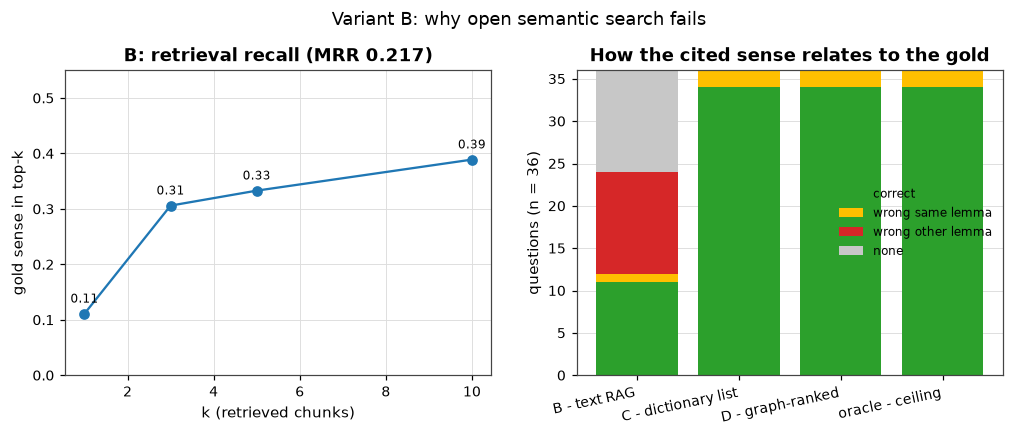

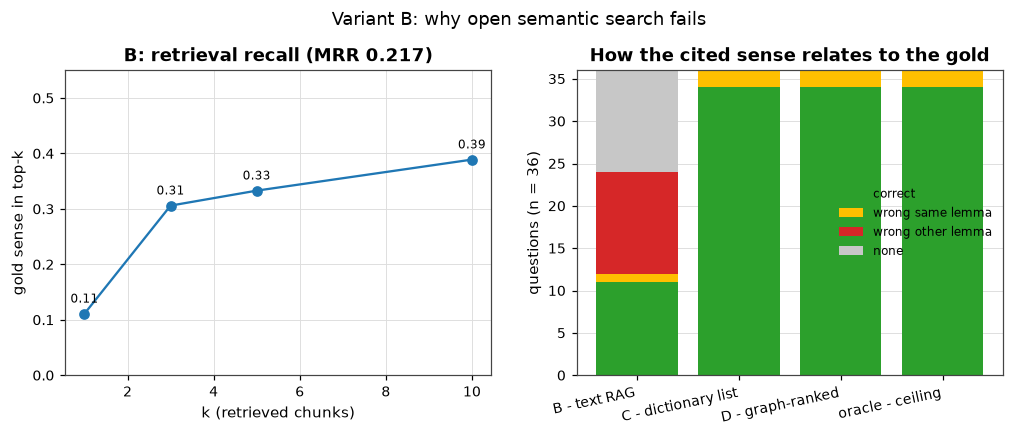

In [5]:
b_metrics = metrics["variants"]["B"]
recall = {int(k): v for k, v in b_metrics["recall_at_k"].items()}
tax = b_metrics["error_taxonomy"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ks = sorted(recall)
ax.plot(ks, [recall[k] for k in ks], "o-", color=al.VARIANT_COLORS["B"])
for k in ks:
    ax.text(k, recall[k] + 0.02, f"{recall[k]:.2f}", ha="center", fontsize=8)
ax.set_xlabel("k (retrieved chunks)")
ax.set_ylabel("gold sense in top-k")
ax.set_ylim(0, 0.55)
ax.set_title(f"B: retrieval recall (MRR {b_metrics['mrr']:.3f})")

ax = axes[1]
cats = ["correct", "wrong_same_lemma", "wrong_other_lemma", "none"]
colors = {"correct": "#2ca02c", "wrong_same_lemma": "#ffbf00", "wrong_other_lemma": "#d62728", "none": "#c7c7c7"}
variants_t = ["B", "C", "D", "oracle"]
bottom = np.zeros(len(variants_t))
for cat in cats:
    vals = np.array([metrics["variants"][v]["error_taxonomy"].get(cat, 0) for v in variants_t])
    ax.bar(np.arange(len(variants_t)), vals, bottom=bottom, label=cat.replace("_", " "), color=colors[cat])
    bottom += vals
ax.set_xticks(np.arange(len(variants_t)), [al.VARIANT_LABELS[v] for v in variants_t])
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
ax.set_ylabel("questions (n = 36)")
ax.set_title("How the cited sense relates to the gold")
ax.legend(fontsize=8, loc="center right")

fig.suptitle("Variant B: why open semantic search fails", y=1.03)
al.save_figure(fig, "02_b_deep_dive")
fig

> **Reading the chart.** B's gold sense reaches the top-10 only **39 %** of the
> time (MRR 0.217). Its citation behaviour splits three ways: 11 correct,
> 1 wrong-but-same-lemma, **12 citations of a different lemma** (the retriever
> pulled in another word's sense and the model cited it) and **12 refusals**
> (`SENSE_ID: none`). The retriever's top-1 pick belongs to the wrong lemma in
> **78 %** of calls.

> **Takeaway 3 (retrieval is the bottleneck).** For lemma-specific sense
> questions, searching the whole 131k-sense inventory by embedding similarity
> is the wrong tool: the first fix is *candidate restriction* (which lemma?),
> not a better ranker. This is exactly what C and D get for free.

## Takeaways from the full-context regime

1. **Saturation.** With candidates given, C = D = oracle = 100 % (excl. trick).
   The graph had no room to help - and we should not expect it to when the
   whole candidate set fits.
2. **Retrieval, not selection, is the bottleneck** for open text RAG (B).
3. **Inventory granularity caps accuracy**: 2/36 items are flawed by
   construction and explain all structured-variant errors here.

So the interesting question becomes: *what happens when the candidate set does
not fit?* That is notebook 3 - and it is where C and D finally diverge.